# Importing Libraries

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore') 

# Data Acquisition

In [15]:
df = pd.read_csv("C:\\Users\\Aalhad Ramteke\\Downloads\\Cleaned_LaptopDataset.csv")

In [16]:
print(f"Dataset Loaded Successfully!")
print(f"The Number of Rows are {df.shape[0]}, and columns are {df.shape[1]}.")

Dataset Loaded Successfully!
The Number of Rows are 1244, and columns are 11.


# Descriptive Statistics

In [17]:
print("Numerical Summary")
df.describe()

Numerical Summary


,inches,ram,weight,price
count,1243.000000,1244.000000,1243.000000,1244.000000
mean,15.138858,8.528135,2.080233,60606.224427
std,1.967382,5.586878,0.814069,37424.636161
min,10.100000,1.000000,0.000200,9270.720000
25%,14.000000,4.000000,1.500000,32655.445200
50%,15.600000,8.000000,2.040000,52693.920000
75%,15.600000,8.000000,2.330000,79813.440000
max,35.600000,64.000000,11.100000,324954.720000


In [18]:
print("\nCategorical Summary")
df.describe(include=['O'])


Categorical Summary


,company,type_name,screen_resolution,cpu,memory,gpu,op_sys
count,1244,1244,1244,1244,1244,1244,1244
unique,19,6,40,118,40,110,9
top,Lenovo,Notebook,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,256GB SSD,Intel HD Graphics 620,Windows 10
freq,282,689,493,183,401,269,1022


# Trends and Patterns in the dataset

In [19]:
print("\nAverage Price by Brand")
print(df.groupby('company')['price'].mean().sort_values(ascending=False))


Average Price by Brand
company
Razer        178282.491429
LG           111834.720000
MSI           91814.548891
Google        89386.080000
Microsoft     85903.788000
Apple         83340.499886
Huawei        75870.720000
Samsung       75308.320000
Toshiba       66747.370213
Dell          63963.889520
Xiaomi        60390.882000
Asus          60310.535581
Lenovo        58486.170179
HP            57910.511520
Fujitsu       38574.720000
Acer          33750.986186
Chuwi         16745.726400
Mediacom      15717.600000
Vero          11584.404000
Name: price, dtype: float64


In [20]:
print("\nAverage Price by Laptop Type")
print(df.groupby('type_name')['price'].mean().sort_values(ascending=False))


Average Price by Laptop Type
type_name
Workstation           121497.525683
Gaming                 92204.328662
Ultrabook              83392.545143
2 in 1 Convertible     68588.775900
Notebook               41937.789172
Netbook                37043.888727
Name: price, dtype: float64


In [21]:
print("\nAverage Price by RAM Capacity")
print(df.groupby('ram')['price'].mean())


Average Price by RAM Capacity
ram
1      53226.720000
2      14849.302500
4      30665.920143
6      33062.559247
8      63361.793829
12     66037.277952
16    103400.887275
24    117553.440000
32    181849.215812
64    117511.526400
Name: price, dtype: float64


# Data Visualization

### Figure 1: Average Price by Laptop Type

<Axes: xlabel='type_name', ylabel='price'>

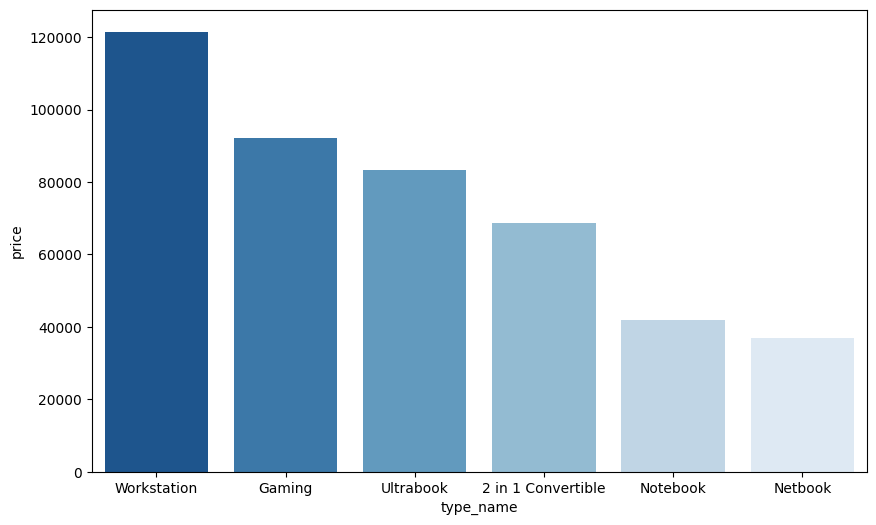

In [22]:
plt.figure(figsize=(10, 6))
type_order = (
    df.groupby('type_name')['price'].mean().sort_values(ascending=False).index
)
sns.barplot(
    x='type_name',
    y='price',
    data=df,
    order=type_order,
    palette='Blues_r',
    ci=None,
)

### Figure 2: RAM vs Price Distribution (Boxplot)

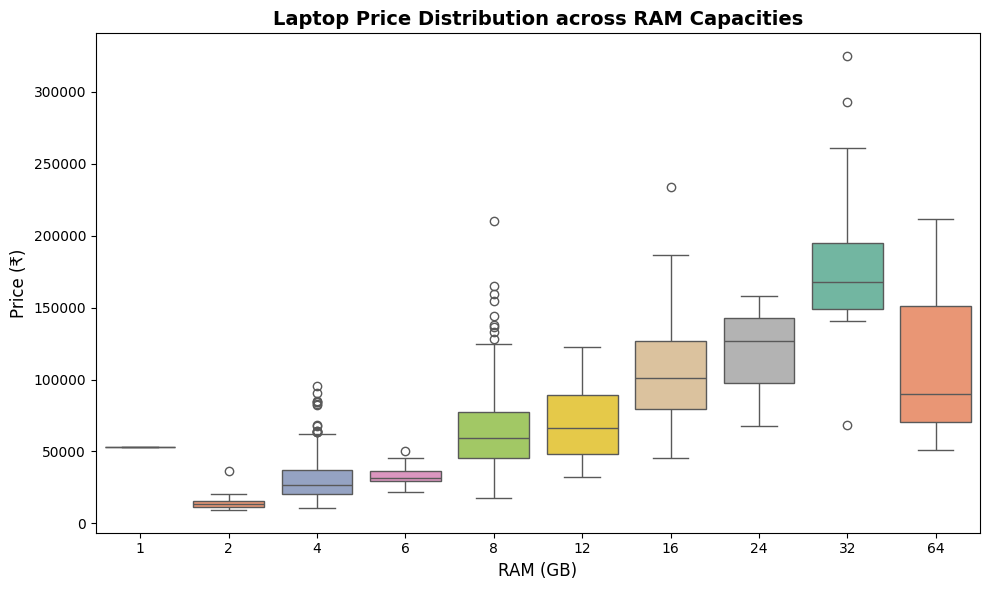

In [23]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    x='ram',
    y='price',
    data=df,
    palette='Set2'
)
plt.title('Laptop Price Distribution across RAM Capacities', fontsize=14, fontweight='bold')
plt.xlabel('RAM (GB)', fontsize=12)
plt.ylabel('Price (₹)', fontsize=12)
plt.tight_layout()
plt.show()

### Figure 3: Average Price by Brand (Top 10)

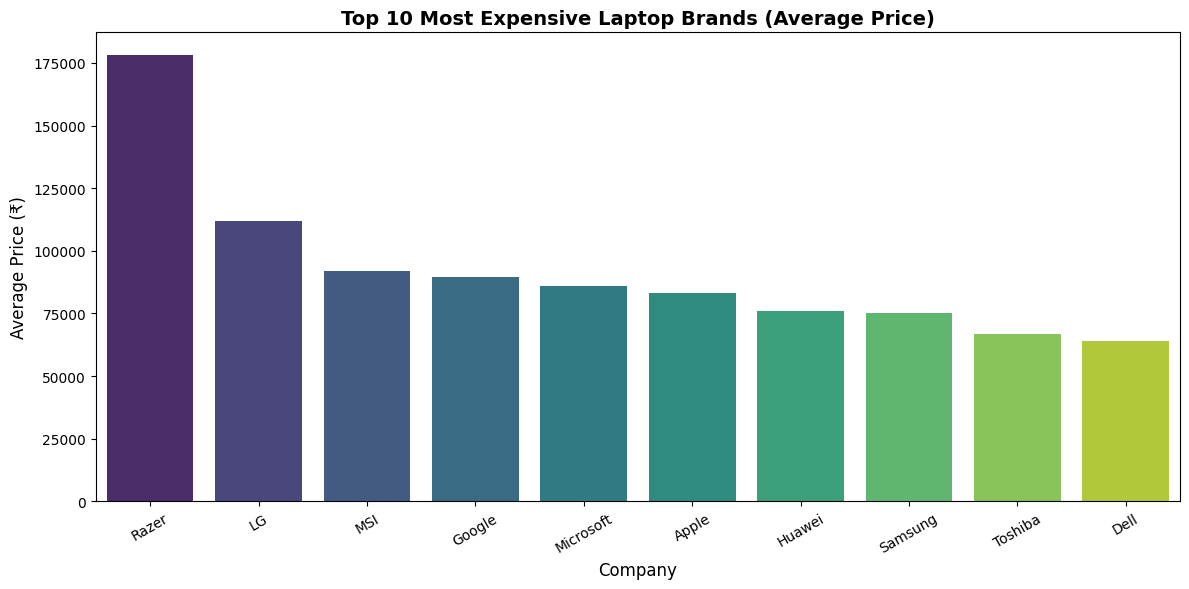

In [24]:
plt.figure(figsize=(12, 6))
top_brands = df.groupby('company')['price'].mean().sort_values(ascending=False).head(10).reset_index()
sns.barplot(x='company', y='price', data=top_brands, palette='viridis')
plt.title('Top 10 Most Expensive Laptop Brands (Average Price)', fontsize=14, fontweight='bold')
plt.xlabel('Company', fontsize=12)
plt.ylabel('Average Price (₹)', fontsize=12)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Figure 4: Weight vs Price Scatter Plot

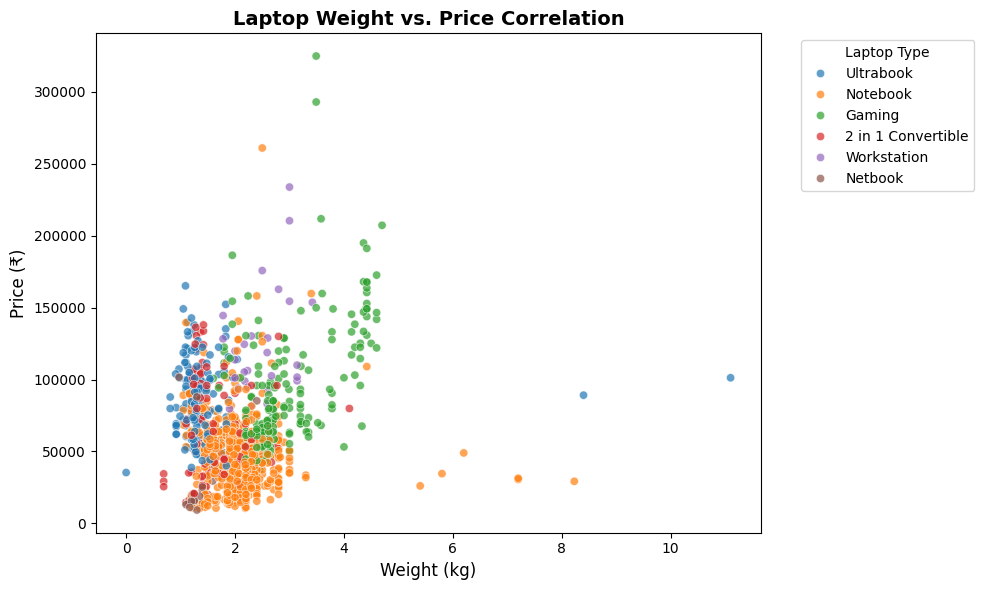

In [25]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='weight', y='price', data=df, hue='type_name', alpha=0.7, palette='tab10')
plt.title('Laptop Weight vs. Price Correlation', fontsize=14, fontweight='bold')
plt.xlabel('Weight (kg)', fontsize=12)
plt.ylabel('Price (₹)', fontsize=12)
plt.legend(title='Laptop Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Figure 5: Screen Size (Inches) Distribution Histogram

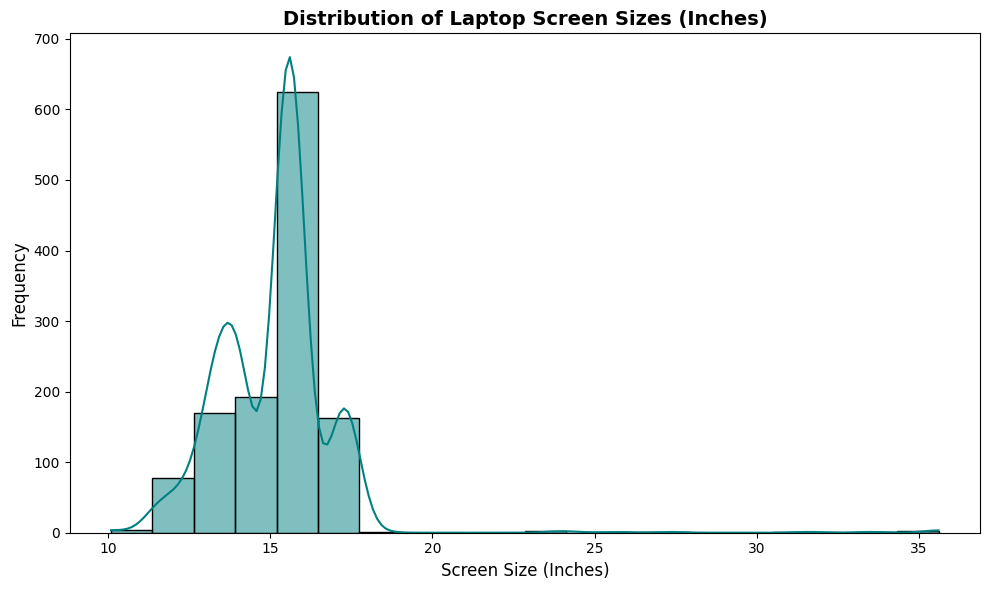

In [26]:
plt.figure(figsize=(10, 6))
sns.histplot(df['inches'], bins=20, kde=True, color='teal')
plt.title('Distribution of Laptop Screen Sizes (Inches)', fontsize=14, fontweight='bold')
plt.xlabel('Screen Size (Inches)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.tight_layout()
plt.show()

## Key Insights generated from Data Visualization

1. **Workstations & Gaming Laptops Cost the Most**:
* **Workstations** (high-end professional machines) have the highest average price at **₹1,21,498**, followed closely by **Gaming** laptops at **₹92,204**.
* On the other hand, everyday **Notebooks** and **Netbooks** are much more budget-friendly, averaging around **₹37,000 to ₹41,900**.


2. **More RAM Means Higher Prices**:
* There is a direct jump in price as RAM increases. Laptops with basic 4GB RAM are inexpensive (~₹30,600), while powerhouse laptops with 16GB or 32GB of RAM shoot up significantly in price (averaging **₹1,03,400** and **₹1,81,849** respectively).


3. **Brand Positioning (Luxury vs. Budget)**:
* Premium specialty brands like **Razer** focus on luxury pricing, averaging **₹1,78,282**.
* Meanwhile, widely used brands like **HP, Lenovo, and Acer** offer a balanced mix of mid-range and budget options, keeping their averages accessible between **₹33,750 and ₹60,300**.


4. **Weight vs. Performance Trade-off**:
* Lighter laptops (under 1.5 kg) are mostly Ultrabooks and Convertibles designed for portability.
* Heavier laptops (above 2.2 kg) are typically Workstations or Gaming units that pack heavy graphics cards and cooling systems, which also drives up their cost.


5. **The 15.6-Inch Sweet Spot**:
* Screen size distribution shows that **15.6-inch** displays are overwhelmingly the market standard for laptops, followed by 14-inch and 13.3-inch sizes.

# Final Business Insights

1. **Mass-market volume is driven by Windows-powered standard notebooks rather than niche operating systems.**

2. **The vast majority of laptops are manufactured with 8GB RAM, making it the industry standard baseline for consumer computing.**

3. **High-performance computing (Gaming and Workstations) is heavily dominated by dedicated graphics hardware rather than basic integrated GPUs.**

4. **Mid-tier pricing between ₹30,000 and ₹80,000 constitutes the highest volume of available products in the retail catalog.**

5. **Standardized screen form factors between 14 and 15.6 inches dominate production, indicating low consumer demand for ultra-small or oversized displays.**